# 10. Diffusion and sedimentation of colloids

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1–5

Leave a bottle of paint, milk or a colloidal suspension standing, and the particles
slowly settle. Gravity pulls them down, Brownian motion spreads them out again,
and the solvent has to flow up to make room for them. If the particles are small,
the competition ends in a sedimentation equilibrium: a concentration that falls
off with height, as the density of the atmosphere does. If they are large, they pile
up at the bottom, and a clear layer of solvent opens above them.

Part III of the book turns from liquids to soft materials, and a suspension is the
simplest one: particles in a solvent. This chapter writes its two functions. The
free energy contains the osmotic pressure of the particles and their weight. The
dissipation is the friction between particles and solvent, which grows as the
particles crowd together. Minimising the Rayleighian, with the constraint that the
mixture as a whole cannot be compressed, gives in one step the equation that
describes all of the above, with the collective diffusion coefficient and the
hindered settling velocity of a concentrated suspension.

The equation has an exact solution for a dilute suspension (Mason and Weaver,
1924), which we use to test two one-parameter approximations, each good in its own
regime. For a concentrated suspension the checks are the equilibrium profile,
which can be computed exactly, and Kynch's theory of the settling front.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.integrate import quad, solve_ivp
from scipy.optimize import brentq

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

## 10.1 The two functions of a suspension

Spherical particles of volume $v_c$ are suspended in a solvent. Their volume
fraction $\phi(z,t)$ depends on the height $z$ only, in a closed vessel with the
bottom at $z = 0$. The particles move with the velocity $v_p(z,t)$ and the solvent
with $v_s(z,t)$.

*Free energy.* Per unit area of the vessel,

$$ A = \int\big[f(\phi) + \Delta\rho\,g\,z\,\phi\big]\,dz , \tag{10.1} $$

where $f(\phi)$ is the free energy of mixing per unit volume and $\Delta\rho$ the
difference between the densities of particle and solvent. The osmotic pressure is
$\Pi = \phi f'(\phi) - f(\phi)$, so that $\phi\,\partial_z f' = \partial_z\Pi$.

*Constraint.* The mixture cannot be compressed. With a closed bottom the volume
flux vanishes everywhere:

$$ \phi v_p + (1 - \phi)\,v_s = 0 . \tag{10.2} $$

The solvent must flow up wherever the particles flow down.

*Dissipation.* The particles and the solvent rub against each other. With a
friction constant $\xi(\phi)$ per unit volume,

$$ \Phi = \frac12\int\xi(\phi)\,(v_p - v_s)^2\,dz . \tag{10.3} $$

In a dilute suspension each particle feels the Stokes friction $\zeta_0 = 6\pi\eta a$,
so $\xi = \zeta_0\phi/v_c$. In a concentrated one the particles obstruct each other's
flow, and $\xi$ grows faster; it is related to the permeability $\kappa$ of the array of
particles by $\xi = \eta/\kappa$ (Section 4.5).

*Minimise.* The rate of change of the free energy is
$\dot A = \int(f' + \Delta\rho gz)\,\partial_t\phi\,dz = \int\phi v_p\,\partial_z(f' + \Delta\rho gz)\,dz$, after
an integration by parts. The constraint (10.2) is imposed with a Lagrange
multiplier $p(z)$, the pressure (Section 3.4). The Rayleighian

$$ R = \Phi + \dot A - \int p\,\partial_z\big[\phi v_p + (1 - \phi)v_s\big]\,dz $$

is minimised over both $v_p$ and $v_s$. The cell below does the algebra at one height.
The result for the flux of particles is

$$ j = \phi v_p = -\frac{v_cK(\phi)}{\zeta_0}\Big(\frac{\partial\Pi}{\partial z} + \Delta\rho\,g\,\phi\Big) , \qquad K(\phi) = \frac{\zeta_0\,\phi\,(1 - \phi)^2}{v_c\,\xi(\phi)} . \tag{10.4} $$

Two forces drive the particles: the gradient of the osmotic pressure and their
weight. The function $K(\phi)$ collects all the hydrodynamics. It equals 1 for a
dilute suspension, and it falls as the suspension becomes denser, both because the
friction grows and because the solvent must flow back past the particles
(the factor $(1 - \phi)^2$).

*Two transport coefficients.* Write $\Pi = (k_BT/v_c)\,\tilde\Pi(\phi)$. Equation (10.4) is a
diffusion equation with drift, $j = -D_c(\phi)\,\partial_z\phi - U(\phi)\,\phi$, with

$$ D_c(\phi) = D_0\,K(\phi)\,\frac{d\tilde\Pi}{d\phi} , \qquad U(\phi) = U_0\,K(\phi) , \qquad D_0 = \frac{k_BT}{\zeta_0} , \quad U_0 = \frac{v_c\Delta\rho g}{\zeta_0} . \tag{10.5} $$

$D_c$ is the *collective* diffusion coefficient, which describes how a gradient of
concentration relaxes. It is the product of a hydrodynamic factor, which falls with
$\phi$, and a thermodynamic factor, the osmotic compressibility, which grows. $U$ is
the *hindered settling* velocity. The same function $K$ appears in both: this is the
generalised Stokes–Einstein relation of Batchelor (1976).

In [2]:
vp, vs, phi, xi, dmu, dp, v_c, zeta0 = sp.symbols("v_p v_s phi xi dmu dp v_c zeta_0")
# Rayleighian density at one height.  dmu = d/dz (f' + Delta rho g z); dp = dp/dz.
# The constraint term, after integration by parts, is + (phi v_p + (1 - phi) v_s) dp.
R = xi * (vp - vs) ** 2 / 2 + phi * vp * dmu + (phi * vp + (1 - phi) * vs) * dp
sol = sp.solve([sp.diff(R, vp), sp.diff(R, vs), phi * vp + (1 - phi) * vs], [vp, vs, dp], dict=True)[0]
flux = sp.factor(phi * sol[vp])
print("pressure gradient:  dp/dz =", sp.factor(sol[dp]))
print("particle flux:      j     =", flux)
K = zeta0 * phi * (1 - phi) ** 2 / (v_c * xi)
print("check of Eq. (10.4) (phi dmu = dPi/dz + Delta rho g phi):", sp.simplify(flux + v_c * K / zeta0 * phi * dmu))

pressure gradient:  dp/dz = -dmu*phi
particle flux:      j     = -dmu*phi**2*(phi - 1)**2/xi
check of Eq. (10.4) (phi dmu = dPi/dz + Delta rho g phi): 0


The pressure gradient $\partial_zp = -\phi\,\partial_z(f' + \Delta\rho gz)$ is the weight of the
particles and the osmotic pressure carried by the solvent: in equilibrium
($j = 0$) it reduces to the hydrostatic pressure of the suspended particles.

*Hard spheres.* For the numbers we use the Carnahan–Starling equation of state of
hard spheres (Carnahan and Starling, 1969) and the Richardson–Zaki law for hindered
settling (Richardson and Zaki, 1954),

$$ \tilde\Pi(\phi) = \phi\,\frac{1 + \phi + \phi^2 - \phi^3}{(1 - \phi)^3} , \qquad K(\phi) = (1 - \phi)^{4.65} . \tag{10.6} $$

At low concentrations Batchelor (1972) found $K = 1 - 6.55\phi$; the Richardson–Zaki
law is an empirical fit for concentrated suspensions.

In [3]:
def osmotic_cs(p):
    return p * (1 + p + p**2 - p**3) / (1 - p) ** 3

def d_osmotic_cs(p):
    return (1 + 4 * p + 4 * p**2 - 4 * p**3 + p**4) / (1 - p) ** 4

def hindrance_rz(p):
    return (1 - p) ** 4.65

print("    phi    Pi v_c/kT   dPi/dphi    K = U/U0    D_c/D0")
for p in (0.0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5):
    print(f"   {p:4.2f}   {osmotic_cs(p):8.3f}   {d_osmotic_cs(p):8.3f}    {hindrance_rz(p):7.4f}    {hindrance_rz(p) * d_osmotic_cs(p):7.3f}")

# a silica suspension in water at 25 C
kT, eta_w, drho, g = 4.11e-21, 0.89e-3, 1000.0, 9.81
print("\n radius   gravitational length   U0           D0           time to fall 1 cm")
for a in (50e-9, 0.25e-6, 1e-6):
    vc, zeta = 4 / 3 * math.pi * a**3, 6 * math.pi * eta_w * a
    lg, U0, D0 = kT / (vc * drho * g), vc * drho * g / zeta, kT / zeta
    print(f" {a * 1e9:5.0f} nm   {lg * 1e6:10.1f} um        {U0 * 1e9:8.2f} nm/s  {D0:.2e} m2/s   {0.01 / U0 / 3600:8.1f} hours")

    phi    Pi v_c/kT   dPi/dphi    K = U/U0    D_c/D0
   0.00      0.000      1.000     1.0000      1.000
   0.05      0.061      1.485     0.7878      1.170
   0.10      0.152      2.189     0.6127      1.341
   0.20      0.481      4.711     0.3543      1.669
   0.30      1.192     10.246     0.1904      1.951
   0.40      2.770     23.222     0.0930      2.159
   0.50      6.500     57.000     0.0398      2.270

 radius   gravitational length   U0           D0           time to fall 1 cm
    50 nm        800.2 um            6.12 nm/s  4.90e-12 m2/s      453.6 hours
   250 nm          6.4 um          153.09 nm/s  9.80e-13 m2/s       18.1 hours
  1000 nm          0.1 um         2449.44 nm/s  2.45e-13 m2/s        1.1 hours


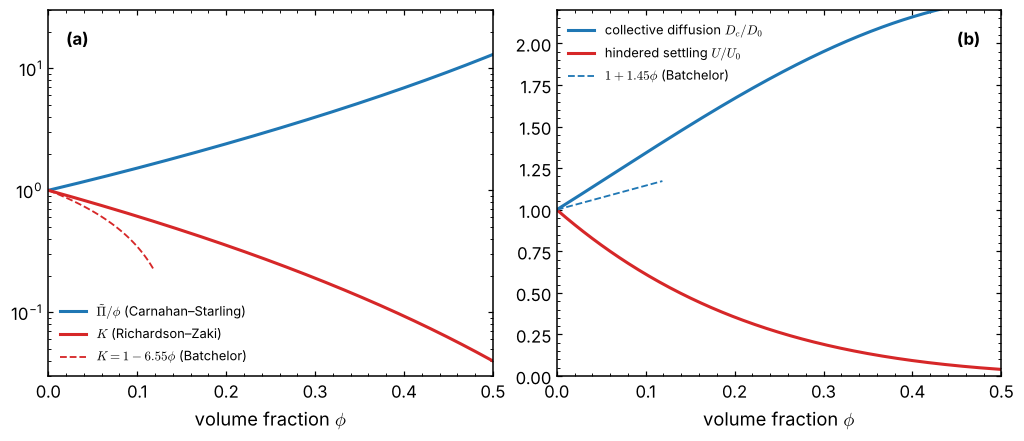

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.9))
pp = np.linspace(1e-4, 0.5, 300)
ax1.semilogy(pp, osmotic_cs(pp) / pp, "C0", lw=2, label=r"$\tilde\Pi/\phi$ (Carnahan–Starling)")
ax1.semilogy(pp, hindrance_rz(pp), "C3", lw=2, label=r"$K$ (Richardson–Zaki)")
ax1.semilogy(pp[pp < 0.12], 1 - 6.55 * pp[pp < 0.12], "C3--", lw=1.2, label=r"$K = 1 - 6.55\phi$ (Batchelor)")
ax1.set_xlabel(r"volume fraction $\phi$"); ax1.set_xlim(0, 0.5); ax1.set_ylim(0.03, 30)
ax1.legend(loc="lower left", fontsize=8.5); on.panel_label(ax1, "(a)", x=0.04, y=0.95)

ax2.plot(pp, hindrance_rz(pp) * d_osmotic_cs(pp), "C0", lw=2, label=r"collective diffusion $D_c/D_0$")
ax2.plot(pp, hindrance_rz(pp), "C3", lw=2, label=r"hindered settling $U/U_0$")
ax2.plot(pp[pp < 0.12], 1 + 1.45 * pp[pp < 0.12], "C0--", lw=1.2, label=r"$1 + 1.45\phi$ (Batchelor)")
ax2.set_xlabel(r"volume fraction $\phi$"); ax2.set_xlim(0, 0.5); ax2.set_ylim(0, 2.2)
ax2.legend(loc="upper left", fontsize=8.5); on.panel_label(ax2, "(b)", x=0.9, y=0.95)
plt.show()

**Figure 10.1.** **(a)** The two ingredients for hard spheres: the osmotic pressure
divided by its ideal value, which grows steeply, and the hindrance function, which
falls. **(b)** Their combinations. Collective diffusion becomes faster as the
suspension becomes denser, because the osmotic pressure pushes harder; settling
becomes slower. The dashed lines are Batchelor's results for a dilute suspension.

## 10.2 Sedimentation equilibrium

In equilibrium the flux (10.4) vanishes:

$$ \frac{d\Pi}{dz} = -\Delta\rho\,g\,\phi . \tag{10.7} $$

The osmotic pressure at a height $z$ carries the weight of all the particles above
it. For a dilute suspension $\Pi = (k_BT/v_c)\,\phi$, and

$$ \phi(z) \propto e^{-z/\ell_g} , \qquad \ell_g = \frac{k_BT}{v_c\,\Delta\rho\,g} = \frac{D_0}{U_0} , \tag{10.8} $$

the barometric law with the *gravitational length* $\ell_g$. The table above shows how
strongly $\ell_g$ depends on the radius, as $a^{-3}$: for silica in water it is 0.8 mm
at a radius of 50 nm, 6 µm at 0.25 µm and 0.1 µm at 1 µm. Small particles stay
suspended over a good part of a test tube; large ones form a sediment a few
particle diameters thick.

For a concentrated suspension, Eq. (10.7) with Eq. (10.6) is integrated numerically
in Section 10.4. Read in reverse, it is a way to measure the equation of state: the
osmotic pressure at each height is the weight of the particles above, so a measured
profile $\phi(z)$ gives $\Pi(\phi)$ (Piazza, Bellini and Degiorgio, 1993; Exercise 4).

## 10.3 Approaching equilibrium: the exact solution and two trials

*Units.* Measure heights in units of the height $L$ of the vessel and times in units
of $L/U_0$, the time a single particle takes to fall through it. For a dilute
suspension, Eq. (10.4) becomes

$$ \frac{\partial\phi}{\partial t} = \frac{\partial}{\partial z}\Big[\frac1\alpha\frac{\partial\phi}{\partial z} + \phi\Big] , \qquad \alpha = \frac{L}{\ell_g} = \frac{LU_0}{D_0} , \tag{10.9} $$

with no flux at $z = 0$ and $z = 1$. The single number $\alpha$, a Péclet number,
measures how strongly gravity wins over diffusion. The suspension starts uniform,
$\phi = 1$ (in units of the mean volume fraction).

*The exact solution.* Mason and Weaver (1924) solved Eq. (10.9) by separation of
variables. The solution approaches the barometric profile through modes that decay
at the rates

$$ \lambda_n = \frac{n^2\pi^2}{\alpha} + \frac{\alpha}{4} , \qquad n = 1, 2, \ldots \tag{10.10} $$

(in units of $U_0/L$); the series is in `on.mason_weaver`. The slowest rate, $\lambda_1$,
is smallest when $\alpha = 2\pi$: the approach to equilibrium is slowest when the
vessel is about six gravitational lengths high.

*The approximation method.* The Rayleighian of Eq. (10.9), in units of $k_BT$ per
particle, is

$$ R = \frac{\alpha}{2}\int\frac{j^2}{\phi}\,dz + \frac{d}{dt}\int\phi\,(\ln\phi + \alpha z)\,dz , \tag{10.11} $$

where the flux follows from the profile by conservation, $j(z) = -\int_0^z\partial_t\phi\,dz'$
(Chapter 5). We try two families of profiles, each with one parameter.

* *Exponential profiles.* $\phi = b\,e^{-bz}/(1 - e^{-b})$, with $b(t)$ growing from 0 (uniform)
  to $\alpha$ (equilibrium). This family describes a suspension in which diffusion
  keeps the profile smooth.
* *A falling front.* Particles fall at the speed $U_0$ and leave clear solvent above
  them; those that reach the bottom form a barometric layer. The profile is 1 below
  a front at the height $h(t)$, 0 above it, plus a layer
  $(1 - h)\,\alpha e^{-\alpha z}/(1 - e^{-\alpha})$ holding the particles that have arrived. The
  parameter $h$ falls from 1 to 0.

Both families contain the initial and the final state. For each, the cell below
computes the free energy $F$ and the friction $\zeta$ of the parameter and integrates
$\zeta\,\dot b = -dF/db$ (or the same for $h$).

In [5]:
Z = np.linspace(0, 1, 4001)

def exponential_trial(alpha, times):
    """One parameter b: phi = b exp(-b z) / (1 - exp(-b))."""
    def profile(b):
        return np.ones_like(Z) if abs(b) < 1e-9 else b * np.exp(-b * Z) / -np.expm1(-b)
    def free_energy(b):
        p = profile(b)
        return np.trapezoid(p * (np.log(p) + alpha * Z), Z)
    def friction(b):
        # flux per unit bdot, j = -dM/db with M(z) = (1 - e^{-bz})/(1 - e^{-b}) the mass below z;
        # written out exactly, because a numerical sum loses all accuracy where phi ~ e^{-b}
        E = -math.expm1(-b)
        j = (Z * np.exp(-b * Z) * E + np.expm1(-b * Z) * math.exp(-b)) / E**2
        return alpha * np.trapezoid(j * j / profile(b), Z)
    def rate(t, y, h=1e-5):
        return [-(free_energy(y[0] + h) - free_energy(y[0] - h)) / (2 * h) / friction(y[0])]
    b = solve_ivp(rate, (0, times[-1]), [1e-4], t_eval=times, rtol=1e-8, atol=1e-10).y[0]
    return b, [profile(x) for x in b]

def front_trial(alpha, times):
    """One parameter h: phi = 1 below the front z = h, plus a barometric layer of the settled particles."""
    E = -math.expm1(-alpha)
    layer = lambda z, h: (1 - h) * alpha * math.exp(-alpha * z) / E
    def free_energy(h):
        below = quad(lambda z: (1 + layer(z, h)) * (math.log(1 + layer(z, h)) + alpha * z), 0, h, limit=200)[0]
        above = quad(lambda z: layer(z, h) * (math.log(layer(z, h)) + alpha * z), h, 1, limit=200)[0]
        return below + above
    def friction(h):
        # flux per unit hdot: below the front the column falls; above it only the layer changes
        j_below = lambda z: -math.expm1(-alpha * z) / E
        j_above = lambda z: -(math.exp(-alpha * z) - math.exp(-alpha)) / E
        return alpha * (quad(lambda z: j_below(z) ** 2 / (1 + layer(z, h)), 0, h, limit=200)[0]
                        + quad(lambda z: j_above(z) ** 2 / layer(z, h), h, 1, limit=200)[0])
    def rate(t, y, d=1e-6):
        h = min(max(y[0], 2 * d), 1 - 2 * d)
        return [-(free_energy(h + d) - free_energy(h - d)) / (2 * d) / friction(h)]
    landed = lambda t, y: y[0] - 1e-4
    landed.terminal = True
    sol = solve_ivp(rate, (0, times[-1]), [1 - 1e-5], t_eval=times, rtol=1e-8, atol=1e-10, events=landed)
    h = np.concatenate((sol.y[0], np.zeros(len(times) - len(sol.t))))
    mean_layer = 1 / alpha - math.exp(-alpha) / E
    return h, h**2 / 2 + (1 - h) * mean_layer               # front height and mean height of the particles

def front_profile(h, alpha, z):
    return (z < h) + (1 - h) * alpha * np.exp(-alpha * z) / -np.expm1(-alpha)

def mean_height(profile):
    return np.trapezoid(Z * profile, Z) / np.trapezoid(profile, Z)

times = np.linspace(0, 2.5, 51)
reference, trials = {}, {}
for alpha in (2.0, 20.0, 200.0):
    edges = np.linspace(0, 1, 2001)
    zc, phi = on.sedimentation_fv(np.ones(2000), edges, times, alpha)
    b, _ = exponential_trial(alpha, times)
    h, front_mean = front_trial(alpha, times)
    exp_profiles = np.array([np.ones_like(zc) if x < 1e-6 else x * np.exp(-x * zc) / -np.expm1(-x) for x in b])
    front_profiles = np.array([front_profile(x, alpha, zc) for x in h])
    reference[alpha] = (zc, phi)
    trials[alpha] = dict(b=b, h=h, exp_profiles=exp_profiles, front_profiles=front_profiles,
                         exp_mean=np.array([np.mean(zc * p) for p in exp_profiles]), front_mean=front_mean,
                         exact_mean=np.array([np.mean(zc * p) for p in phi]),
                         exp_error=np.mean(np.abs(exp_profiles - phi), axis=1),
                         front_error=np.mean(np.abs(front_profiles - phi), axis=1))

print("mean height of the particles  <z>/L   (exact / exponential trial / front trial)")
print("  alpha      t = 0.1                  t = 0.5                  t = 1.0                  t = 2.5")
for alpha, tr in trials.items():
    k = [np.argmin(np.abs(times - t)) for t in (0.1, 0.5, 1.0, 2.5)]
    print(f"  {alpha:5.0f}    " + "   ".join(f"{tr['exact_mean'][i]:.4f}/{tr['exp_mean'][i]:.4f}/{tr['front_mean'][i]:.4f}" for i in k))
print("\nprofile error at t = 0.5:  integral of |phi_trial - phi_exact| dz  (0 = exact, 2 = no overlap)")
for alpha, tr in trials.items():
    print(f"  alpha = {alpha:5.0f}:   exponential trial {tr['exp_error'][10]:.3f}    front trial {tr['front_error'][10]:.3f}")

mean height of the particles  <z>/L   (exact / exponential trial / front trial)
  alpha      t = 0.1                  t = 0.5                  t = 1.0                  t = 2.5
      2    0.4340/0.4347/0.4791   0.3538/0.3534/0.4013   0.3442/0.3441/0.3280   0.3435/0.3435/0.3435
     20    0.4117/0.4192/0.4130   0.1700/0.1775/0.1644   0.0659/0.0578/0.0540   0.0500/0.0500/0.0500
    200    0.4060/0.4174/0.4059   0.1300/0.1453/0.1291   0.0073/0.0050/0.0053   0.0050/0.0050/0.0050

profile error at t = 0.5:  integral of |phi_trial - phi_exact| dz  (0 = exact, 2 = no overlap)
  alpha =     2:   exponential trial 0.006    front trial 0.351
  alpha =    20:   exponential trial 0.369    front trial 0.218
  alpha =   200:   exponential trial 0.960    front trial 0.062


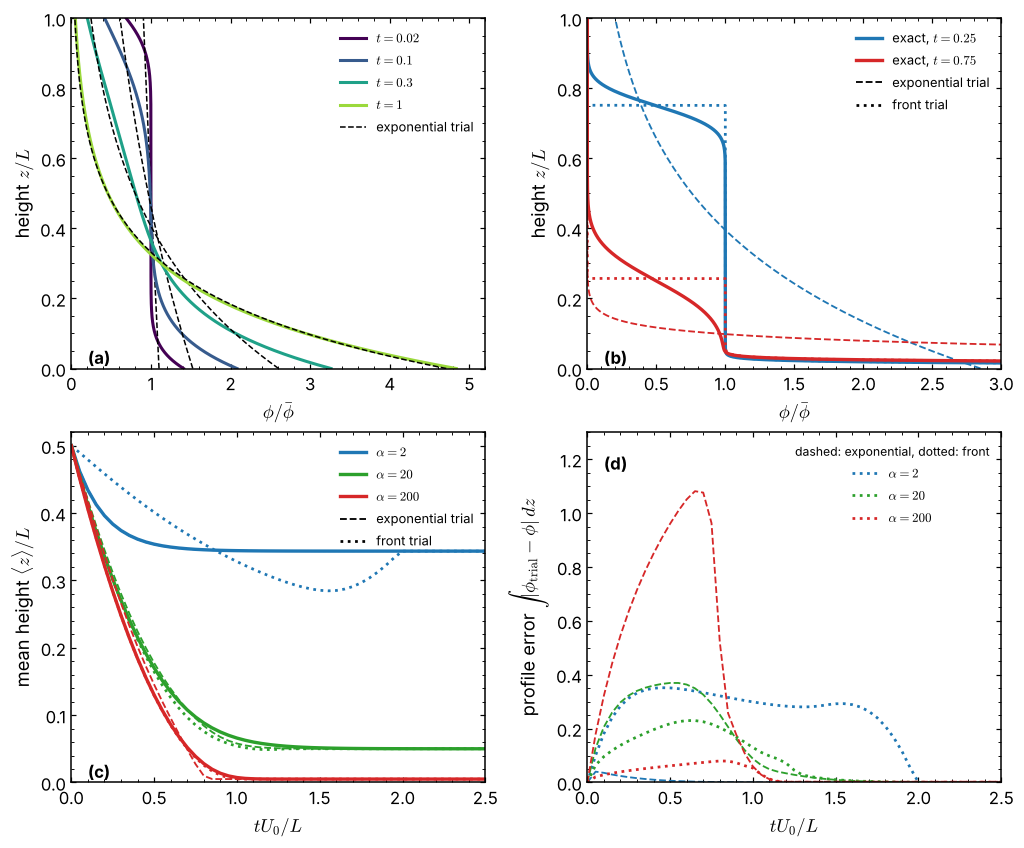

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.6))
ax = axes[0, 0]
alpha = 5.0
t_show = [0.02, 0.1, 0.3, 1.0]
b, profiles = exponential_trial(alpha, np.concatenate(([0.0], t_show)))
for t, p, color in zip(t_show, profiles[1:], plt.cm.viridis(np.linspace(0, 0.85, len(t_show)))):
    ax.plot(on.mason_weaver(Z, t, alpha), Z, color=color, lw=2, label=f"$t = {t:g}$")
    ax.plot(p, Z, "k--", lw=1)
ax.plot([], [], "k--", lw=1, label="exponential trial")
ax.set_xlabel(r"$\phi/\bar\phi$"); ax.set_ylabel("height $z/L$"); ax.set_xlim(0, 5.2); ax.set_ylim(0, 1)
ax.legend(loc="upper right", fontsize=8.5); on.panel_label(ax, "(a)", x=0.04, y=0.06)

ax = axes[0, 1]
zc, phi = reference[200.0]
tr = trials[200.0]
for k, color in zip((5, 15), ("C0", "C3")):
    ax.plot(phi[k], zc, color=color, lw=2.2, label=f"exact, $t = {times[k]:g}$")
    ax.plot(tr["exp_profiles"][k], zc, "--", color=color, lw=1.2)
    ax.plot(tr["front_profiles"][k], zc, ":", color=color, lw=1.8)
ax.plot([], [], "k--", lw=1.2, label="exponential trial"); ax.plot([], [], "k:", lw=1.8, label="front trial")
ax.set_xlabel(r"$\phi/\bar\phi$"); ax.set_ylabel("height $z/L$"); ax.set_xlim(0, 3); ax.set_ylim(0, 1)
ax.legend(loc="upper right", fontsize=8.5); on.panel_label(ax, "(b)", x=0.04, y=0.06)

for ax, key, label in ((axes[1, 0], "mean", "(c)"), (axes[1, 1], "error", "(d)")):
    for (alpha, tr), color in zip(trials.items(), ("C0", "C2", "C3")):
        if key == "mean":
            ax.plot(times, tr["exact_mean"], color=color, lw=2.2, label=rf"$\alpha = {alpha:g}$")
        ax.plot(times, tr["exp_" + key], "--", color=color, lw=1.2)
        ax.plot(times, tr["front_" + key], ":", color=color, lw=1.8,
                label=rf"$\alpha = {alpha:g}$" if key == "error" else None)
    ax.set_xlabel(r"$tU_0/L$"); ax.set_xlim(0, 2.5)
    on.panel_label(ax, label, x=0.04, y=0.06 if key == "mean" else 0.94)
axes[1, 0].plot([], [], "k--", lw=1.2, label="exponential trial"); axes[1, 0].plot([], [], "k:", lw=1.8, label="front trial")
axes[1, 0].set_ylabel(r"mean height $\langle z\rangle/L$"); axes[1, 0].set_ylim(0, 0.52)
axes[1, 0].legend(loc="upper right", fontsize=8.5)
axes[1, 1].set_ylabel(r"profile error $\int|\phi_{\rm trial} - \phi|\,dz$"); axes[1, 1].set_ylim(0, 1.3)
axes[1, 1].legend(loc="upper right", fontsize=8.5, title="dashed: exponential, dotted: front", title_fontsize=8)
plt.show()

**Figure 10.2.** The two trials against the exact solution. **(a)** Profiles for
$\alpha = 5$: exact (colours) and exponential trial (dashed). **(b)** Profiles for
$\alpha = 200$ at $t = 0.25$ and $0.75$: exact (full), exponential trial (dashed), front trial
(dotted). **(c)** Mean height of the particles for three values of $\alpha$. **(d)** Error
of the profile, $\int|\phi_{\rm trial} - \phi|\,dz$, which is 2 for profiles that do not
overlap at all.

The figure repeats the lesson of Chapter 5 with a new twist: *a trial must contain
the right picture of the process*, and the mean height alone does not tell whether
it does. By the mean height, panel (c), both trials look reasonable at every $\alpha$
except the front trial at $\alpha = 2$. The profiles tell a sharper story, panels (b)
and (d).

* When diffusion is strong ($\alpha = 2$) the profile is smooth at all times, and the
  exponential family captures it almost exactly: the mean height is right to within
  0.0012, and the profile error, largest at the start when the exact profile has
  thin boundary layers, is never above 0.04. The front trial is qualitatively
  wrong here; its mean height overshoots and comes back, because its front must
  reach the bottom before its particles can spread out.
* When gravity dominates ($\alpha = 200$), particles fall as a block at the speed $U_0$,
  and a front separates the suspension from clear solvent. A smooth exponential
  cannot form a front. It still gets the mean height to within 0.02, because the
  free energy it lowers is mostly the gravitational energy, which depends on the
  mean height alone; but its profile is badly wrong (error up to 1.08, out of a
  maximum of 2). The front trial gets the falling block right: its mean height is
  within 0.003 and its profile error below 0.08.
* In between ($\alpha = 20$) the front is blurred over a few gravitational lengths, and
  neither trial is good.

The variational principle picks the best member of the family, but it cannot add
physics the family does not contain. Choosing the trial is choosing the physics.

## 10.4 A concentrated suspension

In a concentrated suspension Eq. (10.4) becomes, in the same units,

$$ \frac{\partial\phi}{\partial t} = \frac{\partial}{\partial z}\Big\{K(\phi)\Big[\frac1\alpha\frac{\partial\tilde\Pi}{\partial z} + \phi\Big]\Big\} , \tag{10.12} $$

with the functions (10.6). The function `on.sedimentation_fv` solves it by finite
volumes.

When $\alpha$ is large, diffusion matters only where the concentration changes
sharply, and the equation is close to the conservation law
$\partial_t\phi + \partial_z[\phi U(\phi)] = 0$ studied by Kynch (1952). Its main prediction is
simple. The upper edge of a suspension of uniform volume fraction $\phi_0$ falls at
the hindered velocity,

$$ \dot h = -U_0\,K(\phi_0) , \tag{10.13} $$

and the suspension below it remains uniform until the front meets the sediment
that grows from the bottom. The sediment ends in the equilibrium profile of
Eq. (10.7). The cell below follows a suspension with $\phi_0 = 0.1$ in a vessel
$\alpha = 60$ gravitational lengths high.

In [7]:
phi_0, alpha_c = 0.1, 60.0
edges = np.linspace(0.0, 1.0, 1601)
zc = 0.5 * (edges[1:] + edges[:-1])
t_conc = np.concatenate((np.linspace(0, 1.6, 33), [3.0, 6.0, 12.0]))
zc, phi_c = on.sedimentation_fv(np.full_like(zc, phi_0), edges, t_conc, alpha_c, osmotic_cs, hindrance_rz)

def front_height(profile):
    """Highest point where the volume fraction exceeds phi_0 / 2."""
    return zc[np.where(profile > phi_0 / 2)[0].max()]

def sediment_top(profile):
    above = np.where(profile > 1.5 * phi_0)[0]
    return zc[above.max()] if len(above) else 0.0

def equilibrium_profile(alpha, mean, z):
    """Eq. (10.7) in the units of Eq. (10.12): dphi/dz = -alpha phi / Pi'(phi), with the given mean."""
    def integrate(log_top):
        return solve_ivp(lambda s, y: [-alpha * y[0] / d_osmotic_cs(y[0])], (1, 0), [math.exp(log_top)],
                         dense_output=True, rtol=1e-11, atol=1e-14)
    def excess(log_top):
        zz = np.linspace(0, 1, 4001)
        return np.trapezoid(integrate(log_top).sol(zz)[0], zz) - mean
    return integrate(brentq(excess, -60, math.log(0.9))).sol(z)[0]

eq_c = equilibrium_profile(alpha_c, phi_0, zc)
print(f"particles conserved to {np.ptp(phi_c.sum(axis=1)) * (zc[1] - zc[0]):.1e}")
print(f"hindered velocity K(phi_0) = {hindrance_rz(phi_0):.4f} U0")
print("    t      front     Eq. (10.13)    top of the sediment")
for k in range(2, 33, 4):
    print(f"  {t_conc[k]:4.2f}    {front_height(phi_c[k]):.4f}      {1 - hindrance_rz(phi_0) * t_conc[k]:.4f}        {sediment_top(phi_c[k]):.3f}")
for k in (-3, -2, -1):
    print(f"t = {t_conc[k]:4.1f}:  largest difference from the equilibrium profile {np.max(np.abs(phi_c[k] - eq_c)):.1e}")
print(f"equilibrium: volume fraction at the bottom {eq_c[0]:.3f}, osmotic pressure there {osmotic_cs(eq_c[0]):.2f} kT/v_c"
      f" (alpha * phi_0 = {alpha_c * phi_0:.2f})")

particles conserved to 3.4e-15
hindered velocity K(phi_0) = 0.6127 U0
    t      front     Eq. (10.13)    top of the sediment
  0.10    0.9434      0.9387        0.050
  0.30    0.8209      0.8162        0.121
  0.50    0.6991      0.6937        0.177
  0.70    0.5772      0.5711        0.225
  0.90    0.4566      0.4486        0.266
  1.10    0.3634      0.3261        0.282
  1.30    0.3247      0.2035        0.275
  1.50    0.3091      0.0810        0.267
t =  3.0:  largest difference from the equilibrium profile 1.1e-04
t =  6.0:  largest difference from the equilibrium profile 1.2e-06
t = 12.0:  largest difference from the equilibrium profile 1.2e-06
equilibrium: volume fraction at the bottom 0.491, osmotic pressure there 5.99 kT/v_c (alpha * phi_0 = 6.00)


The numbers follow the picture. The upper edge falls at the hindered velocity,
$0.61\,U_0$, staying within $0.008\,L$ of Eq. (10.13) (slightly above it, because
diffusion blurs the edge) until it meets the sediment near $t = 1$, at about a third
of the height. Without hindrance the particles would have reached the bottom by
$t = 1$. After the front has met the sediment, the sediment settles slowly into its
equilibrium, which it reaches to $10^{-6}$ by $t = 6$. At the bottom the osmotic
pressure is $6.0\,k_BT/v_c$, the weight of all the particles above ($\alpha\phi_0$ in these
units), as Eq. (10.7) requires.

The volume fraction at the bottom, 0.49, is close to the freezing point of hard
spheres, 0.494. In a taller vessel the bottom of the sediment would crystallise,
which the equation of state of the fluid used here does not describe.

## 10.5 Checks

Figure 10.3 collects the checks of this chapter: the numerical solution against the
exact solution of Mason and Weaver, and the concentrated suspension against Kynch's
front velocity and the exact equilibrium profile.

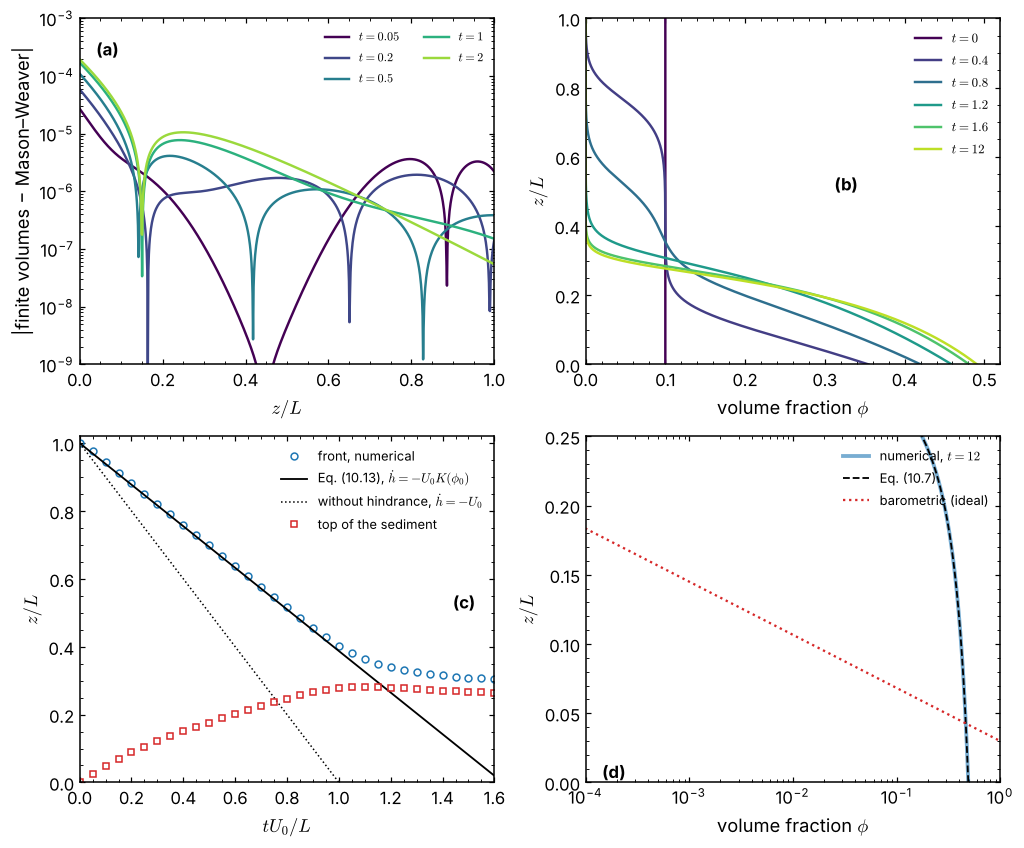

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.6))

ax = axes[0, 0]
alpha = 10.0
edges_d = np.linspace(0, 1, 801)
t_check = np.array([0.0, 0.05, 0.2, 0.5, 1.0, 2.0])
zd, phi_d = on.sedimentation_fv(np.ones(800), edges_d, t_check, alpha)
for k, color in zip(range(1, len(t_check)), plt.cm.viridis(np.linspace(0, 0.85, len(t_check) - 1))):
    ax.semilogy(zd, np.abs(phi_d[k] - on.mason_weaver(zd, t_check[k], alpha)) + 1e-12, color=color, label=f"$t = {t_check[k]:g}$")
ax.set_xlabel("$z/L$"); ax.set_ylabel("|finite volumes − Mason–Weaver|"); ax.set_xlim(0, 1); ax.set_ylim(1e-9, 1e-3)
ax.legend(loc="upper right", fontsize=8, ncol=2); on.panel_label(ax, "(a)", x=0.04, y=0.94)

ax = axes[0, 1]
for k, color in zip((0, 8, 16, 24, 32, -1), plt.cm.viridis(np.linspace(0, 0.9, 6))):
    ax.plot(phi_c[k], zc, color=color, label=f"$t = {t_conc[k]:g}$")
ax.set_xlabel(r"volume fraction $\phi$"); ax.set_ylabel("$z/L$"); ax.set_xlim(0, 0.52); ax.set_ylim(0, 1)
ax.legend(loc="upper right", fontsize=8.5); on.panel_label(ax, "(b)", x=0.6, y=0.55)

ax = axes[1, 0]
fronts = [front_height(p) for p in phi_c[:33]]
sediments = [sediment_top(p) for p in phi_c[:33]]
ax.plot(t_conc[:33], fronts, "C0o", mfc="none", ms=4.5, label="front, numerical")
ax.plot(t_conc[:33], 1 - hindrance_rz(phi_0) * t_conc[:33], "k-", lw=1.2, label=r"Eq. (10.13), $\dot h = -U_0K(\phi_0)$")
ax.plot(t_conc[:33], 1 - t_conc[:33], "k:", lw=1, label=r"without hindrance, $\dot h = -U_0$")
ax.plot(t_conc[:33], sediments, "C3s", mfc="none", ms=4, label="top of the sediment")
ax.set_xlabel(r"$tU_0/L$"); ax.set_ylabel("$z/L$"); ax.set_xlim(0, 1.6); ax.set_ylim(0, 1.02)
ax.legend(loc="upper right", fontsize=8.5); on.panel_label(ax, "(c)", x=0.9, y=0.55)

ax = axes[1, 1]
ax.semilogx(phi_c[-1], zc, "C0", lw=2.5, alpha=0.6, label="numerical, $t = 12$")
ax.semilogx(eq_c, zc, "k--", lw=1.2, label="Eq. (10.7)")
dilute = alpha_c * phi_0 * np.exp(-alpha_c * zc) / -np.expm1(-alpha_c)
ax.semilogx(dilute, zc, "C3:", lw=1.5, label="barometric (ideal)")
ax.set_xlabel(r"volume fraction $\phi$"); ax.set_ylabel("$z/L$"); ax.set_xlim(1e-4, 1); ax.set_ylim(0, 0.25)
ax.legend(loc="upper right", fontsize=8.5); on.panel_label(ax, "(d)", x=0.04, y=0.06)
plt.show()

**Figure 10.3.** Checks. **(a)** Difference between the finite-volume solution of
Eq. (10.9) and the exact solution of Mason and Weaver, for $\alpha = 10$. **(b)** A
concentrated suspension of hard spheres ($\phi_0 = 0.1$, $\alpha = 60$) settling: profiles
at increasing times. **(c)** Height of the upper edge of the suspension (symbols)
against Kynch's prediction (10.13), and the top of the growing sediment.
**(d)** The final state against the equilibrium profile (10.7), on a logarithmic
scale. The barometric profile of an ideal suspension (dotted) would pack the
particles far more densely at the bottom; the osmotic pressure of hard spheres holds
the sediment up.

With 800 cells the finite-volume solution differs from the exact series by at most
$2\times10^{-4}$ (the profile itself reaches 10 at the bottom), and the difference falls
as the square of the cell size. The same solver is used for the concentrated
suspension, whose upper edge follows Kynch's velocity to within $0.008\,L$ and whose
final state lies on the equilibrium profile to $10^{-6}$.

## 10.6 What to trust

* *The hindrance function.* The Richardson–Zaki law is a fit to experiments. For a
  dilute suspension Batchelor (1972) found $K = 1 - 6.55\phi$, whereas the fit gives
  $1 - 4.65\phi$. The numbers of Section 10.4 depend on this choice; the structure of
  the theory does not, and any $K(\phi)$ can be used.
* *The equation of state.* The Carnahan–Starling equation describes the fluid. Above
  $\phi \approx 0.494$ hard spheres crystallise, and the bottom of a taller sediment
  would need the equation of state of the crystal.
* *Mean values.* The equation is for the mean concentration. The velocities of
  individual particles fluctuate about the mean through their hydrodynamic
  interactions, and in a polydisperse suspension, where large particles fall faster,
  the upper edge is blurred. Particles that attract each other, which flocculate and
  form gels, are left out.
* *The trials.* A one-parameter trial is accurate when its shape has the right
  physics: a smooth exponential when diffusion wins, a falling front when gravity
  does. In between neither is accurate, and a trial with both features is needed.

## Summary

* A suspension has two functions: the free energy of mixing plus the weight of the
  particles, and the friction between particles and solvent. Incompressibility,
  imposed with the pressure as a Lagrange multiplier, makes the solvent flow back.
* The particle flux is $j = -(v_cK/\zeta_0)(\partial_z\Pi + \Delta\rho g\phi)$. One hydrodynamic
  function $K(\phi)$ gives both the collective diffusion coefficient
  $D_c = D_0K\,d\tilde\Pi/d\phi$ and the hindered settling velocity $U = U_0K$.
* In equilibrium the osmotic pressure carries the weight of the particles above;
  for a dilute suspension the profile is barometric with the gravitational length
  $\ell_g = k_BT/v_c\Delta\rho g$.
* The approach to equilibrium depends on one number, $\alpha = L/\ell_g$. A one-parameter
  trial works when it has the right picture of the process: a smooth exponential
  when diffusion dominates, a falling front when gravity does.
* In a concentrated suspension the upper edge falls at the hindered velocity
  $U_0K(\phi_0)$, and the sediment reaches the equilibrium profile set by the
  equation of state.

## Exercises

Sample solutions are in [`solutions/part3_soft_materials/10_solutions.ipynb`](../../solutions/part3_soft_materials/10_solutions.ipynb).

1. **The ultracentrifuge.** In a centrifuge spinning at the angular velocity $\omega$ the
   force on a particle is $v_c\Delta\rho\,\omega^2r$ at the distance $r$ from the axis. Show
   that the equilibrium profile of a dilute solution is
   $c(r) \propto \exp[v_c\Delta\rho\,\omega^2r^2/2k_BT]$, so that the slope of $\ln c$ against $r^2$
   gives the buoyant mass. For a protein of molar mass 66 kg/mol and partial specific
   volume 0.73 mL/g in water at 20 °C, spinning at 12 000 rpm, find the ratio of the concentrations at
   $r = 7.0$ cm and $r = 6.5$ cm.
2. **Batchelor's diffusion coefficient.** Use the virial expansion of the osmotic
   pressure of hard spheres, $\tilde\Pi = \phi + 4\phi^2 + O(\phi^3)$, and Batchelor's
   $K = 1 - 6.55\phi$ to show that $D_c = D_0(1 + 1.45\phi)$ to first order. What does the
   Richardson–Zaki law give instead? Why does the collective diffusion coefficient
   grow with concentration while the settling velocity falls?
3. **How long does equilibrium take?** (a) Linearise the exponential trial about its
   equilibrium $b = \alpha$ and compare its relaxation rate with the exact slowest rate
   $\lambda_1$ of Eq. (10.10), for $\alpha$ from 0.1 to 100. (b) Weaver (1926) argued that a
   uniform suspension reaches its equilibrium in about the time a particle takes to
   fall two heights of the vessel. Compute, from the exact solution, the time at
   which the profile is everywhere within 1 % of equilibrium, and test the rule.
4. **An equation of state from a sedimentation profile.** Take the computed
   equilibrium profile of Section 10.4, add 1 % random noise to it, and recover
   $\tilde\Pi(\phi)$ from Eq. (10.7) by integrating the weight of the particles from the
   top. Compare the result with the Carnahan–Starling equation of state. Where is
   the method least accurate, and why?

## Suggested references

* M. Doi, *Soft Matter Physics* (Oxford University Press, 2013).
* W. B. Russel, D. A. Saville and W. R. Schowalter, *Colloidal Dispersions* (Cambridge University Press, 1989).
* M. Mason and W. Weaver, "The settling of small particles in a fluid", *Phys. Rev.* **23**, 412 (1924).
* W. Weaver, "The duration of the transient state in the settling of small particles", *Phys. Rev.* **27**, 499 (1926).
* G. J. Kynch, "A theory of sedimentation", *Trans. Faraday Soc.* **48**, 166 (1952).
* J. F. Richardson and W. N. Zaki, "Sedimentation and fluidisation: Part I", *Trans. Inst. Chem. Eng.* **32**, 35 (1954).
* N. F. Carnahan and K. E. Starling, "Equation of state for nonattracting rigid spheres", *J. Chem. Phys.* **51**, 635 (1969).
* G. K. Batchelor, "Sedimentation in a dilute dispersion of spheres", *J. Fluid Mech.* **52**, 245 (1972).
* G. K. Batchelor, "Brownian diffusion of particles with hydrodynamic interaction", *J. Fluid Mech.* **74**, 1 (1976).
* R. Piazza, T. Bellini and V. Degiorgio, "Equilibrium sedimentation profiles of screened charged colloids: a test of the hard-sphere equation of state", *Phys. Rev. Lett.* **71**, 4267 (1993).

---

**Previous:** [9. A drying droplet](../part2_liquids_interfaces/09_drying_droplet.ipynb) &nbsp;·&nbsp; **Next:** [11. Swelling and squeezing of a gel](11_gel_swelling.ipynb)